# Phase 2 : Notebook 1

In this notebook I try to follow the setup used in the paper as closely as possible. I use the same dataset and the same four models with their default settings since the paper does not mention any specific parameters. I also do not apply scaling in this notebook. After replicating their approach, I will compare the results with a second notebook where I make the necessary corrections to the pipeline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

In [2]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('faults.csv')
print(df.shape)
df.head()

Saving faults.csv to faults.csv
(1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [3]:
# the 7 defect types are one hot encoded in 7 columns
# so i combine them into one column called Defect_Type
class_cols = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
df['Defect_Type'] = df[class_cols].idxmax(axis=1)

# the 27 features are all the other columns
feature_cols = [c for c in df.columns if c not in class_cols + ['Defect_Type']]

X = df[feature_cols]
y = df['Defect_Type']

print(X.shape)
print(y.value_counts())

(1941, 27)
Defect_Type
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64


The paper mentions a 95/5 train-test split but the confusion matrix in Figure 5 of the paper adds up to 180 test samples. Their reported accuracy of 79.44% also matches 143 correct predictions out of 180. So I use 180 test samples to get as close as possible to what they actually did. I do not use stratification since the paper does not mention it.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=180, random_state=42)

print("train size:", len(X_train))
print("test size:", len(X_test))
print(y_test.value_counts())

train size: 1761
test size: 180
Defect_Type
Other_Faults    62
Bumps           36
K_Scatch        35
Z_Scratch       23
Pastry          13
Stains           7
Dirtiness        4
Name: count, dtype: int64


I use the default settings for all four models and do not apply scaling since the paper does not mention any specific parameters or preprocessing details. I fix the random_state so the results can be reproduced.

In [5]:
def make_models():
    models = {
        'Logistic Regression': LogisticRegression(),
        'Decision Tree': DecisionTreeClassifier(random_state=42),
        'SVM': SVC(),
        'Random Forest': RandomForestClassifier(random_state=42)
    }
    return models

models = make_models()

## Metrics

$$\text{Accuracy} = \frac{\text{correct predictions}}{\text{all predictions}}$$

For each class $c$:

$$\text{Precision}_c = \frac{TP_c}{TP_c + FP_c} \qquad \text{Recall}_c = \frac{TP_c}{TP_c + FN_c} \qquad F1_c = 2 \cdot \frac{\text{Precision}_c \cdot \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c}$$

Macro F1 gives every class the same weight:

$$\text{Macro F1} = \frac{1}{7}\sum_{c=1}^{7} F1_c$$

In [6]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred) * 100
    mp, mr, mf, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    wp, wr, wf, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)

    results.append([name, acc, mp, mr, mf, wp, wr, wf])

results_df = pd.DataFrame(results, columns=['Model', 'Accuracy (%)', 'Macro Precision', 'Macro Recall',
                                            'Macro F1', 'Weighted Precision', 'Weighted Recall', 'Weighted F1'])
results_df = results_df.round(2)
results_df

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy (%),Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression,46.11,0.21,0.28,0.24,0.35,0.46,0.39
1,Decision Tree,73.89,0.77,0.78,0.77,0.75,0.74,0.74
2,SVM,48.89,0.25,0.27,0.24,0.40,0.49,0.41
3,Random Forest,78.33,0.81,0.78,0.79,0.79,0.78,0.78


In [7]:
# accuracy values from Table 4 in the paper
paper_acc = [74.44, 77.77, 74.44, 79.44]

compare = results_df[['Model', 'Accuracy (%)']].copy()
compare['Paper Accuracy (%)'] = paper_acc
compare['Difference'] = (compare['Accuracy (%)'] - compare['Paper Accuracy (%)']).round(2)
compare

,Model,Accuracy (%),Paper Accuracy (%),Difference
0,Logistic Regression,46.11,74.44,-28.33
1,Decision Tree,73.89,77.77,-3.88
2,SVM,48.89,74.44,-25.55
3,Random Forest,78.33,79.44,-1.11


Decision Tree and Random Forest give results close to what the paper reports but Logistic Regression and SVM perform much worse with accuracy of only 46-49% compared to the paper's 74.44% for both. Logistic Regression also gives a ConvergenceWarning which means the model did not fully converge during training.

The paper does not mention which random split was used so I repeat the experiment with 30 different random splits to see how much the accuracy changes depending on the split.

Since each test set has 180 samples the accuracy can vary by chance. The standard error for the accuracy on $(n)$ test samples is approximately

$$SE = \sqrt{\frac{p(1-p)}{n}}$$

For $p \approx 0.78$ and $n = 180$ this is about 3.1 percentage points. This helps me check how consistent the results are across different splits.

In [8]:
warnings.filterwarnings('ignore')

all_acc = {'Logistic Regression': [], 'Decision Tree': [], 'SVM': [], 'Random Forest': []}

for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=180, random_state=seed)
    new_models = make_models()
    for name, model in new_models.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        all_acc[name].append(accuracy_score(yte, pred) * 100)

seed_df = pd.DataFrame(all_acc)
print(seed_df.agg(['mean', 'std', 'min', 'max']).T.round(2))

                      mean   std    min    max
Logistic Regression  44.50  3.71  38.33  52.78
Decision Tree        71.76  3.57  64.44  80.00
SVM                  50.87  4.38  43.89  58.33
Random Forest        78.48  2.84  72.78  83.33


The accuracy varies by around 3 to 4 percentage points between different splits based on the standard deviation. This means that small differences in accuracy between models could simply be due to the split used rather than the models themselves.

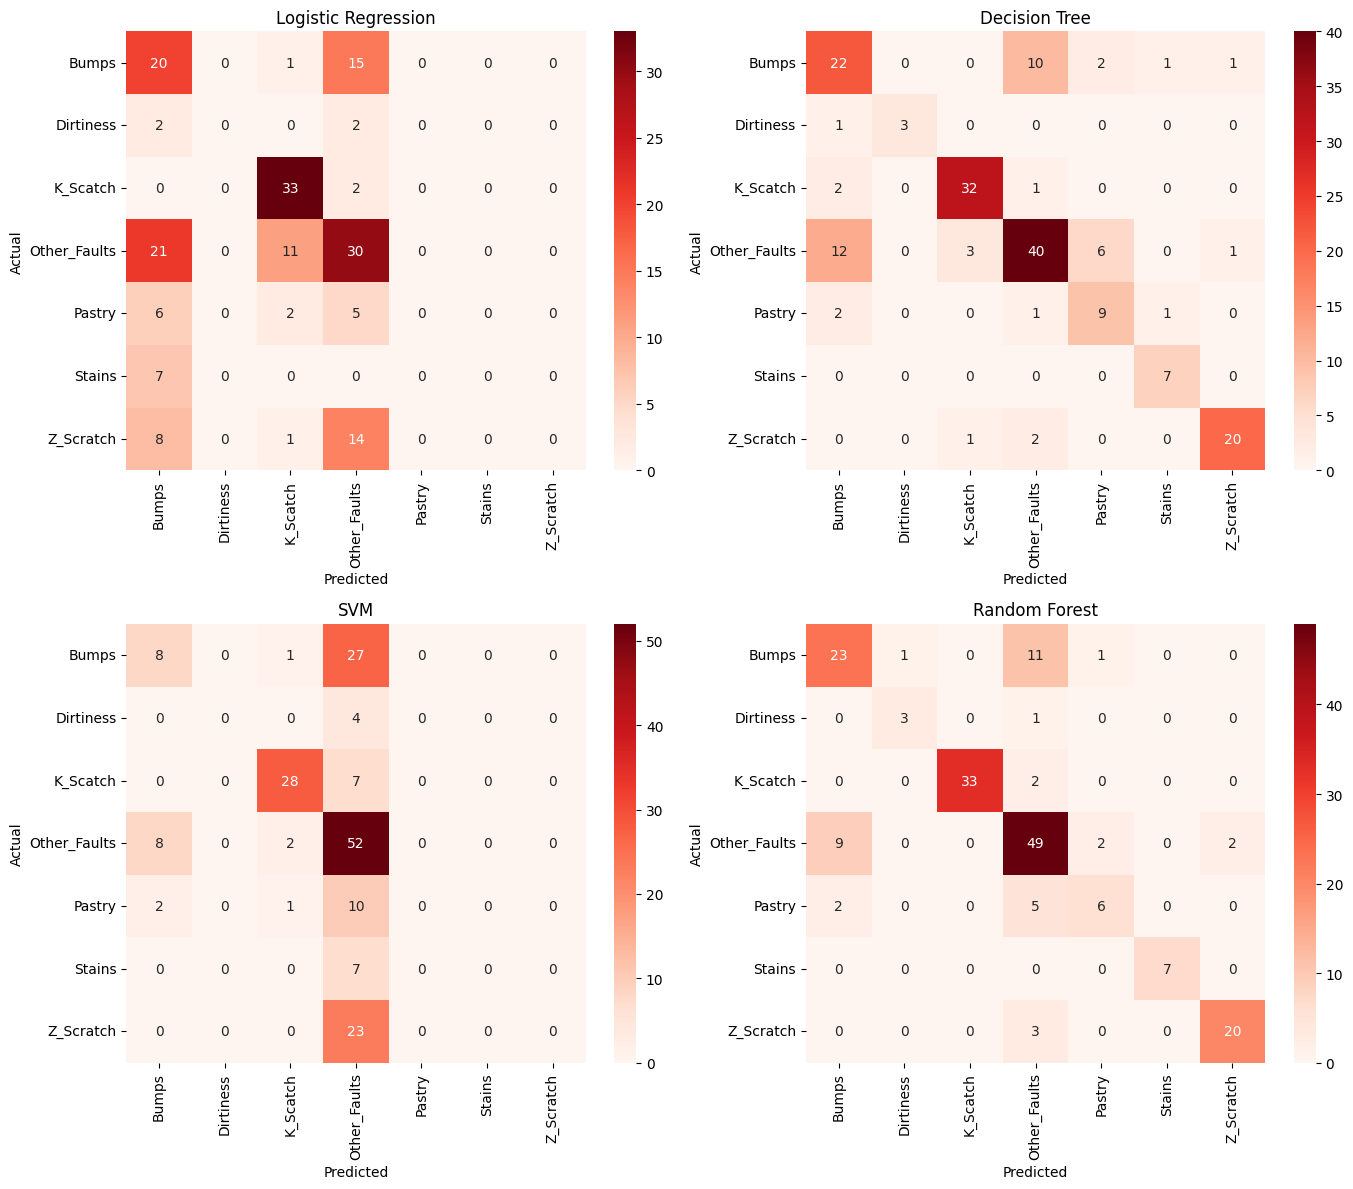

In [9]:
class_names = sorted(y.unique())

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
                xticklabels=class_names, yticklabels=class_names, ax=axes[i])
    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

Logistic Regression and SVM get no correct predictions for Dirtiness, Pastry, Stains and Z_Scratch. SVM has 48.89% accuracy but only 0.24 macro F1.

I test whether scaling improves the results for Logistic Regression and SVM. I use standardisation based on the training data only using its mean and standard deviation:

$$z = \frac{x - \mu_{train}}{\sigma_{train}}$$

Logistic Regression uses $(z = w^T x + b)$ while SVM with the RBF kernel relies on distances:

$$K(x, x') = \exp\left(-\gamma \, \lVert x - x' \rVert^2\right)$$

Without scaling features with much larger values can dominate both models. Decision trees should not be affected much by scaling since they split features based on thresholds.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_results = []
for name, model in make_models().items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred) * 100
    mp, mr, mf, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    scaled_results.append([name, acc, mf])

scaled_df = pd.DataFrame(scaled_results, columns=['Model', 'Scaled Accuracy (%)', 'Scaled Macro F1']).round(2)
scaled_df['Unscaled Accuracy (%)'] = results_df['Accuracy (%)'].values
scaled_df['Paper Accuracy (%)'] = paper_acc
scaled_df

,Model,Scaled Accuracy (%),Scaled Macro F1,Unscaled Accuracy (%),Paper Accuracy (%)
0,Logistic Regression,72.22,0.70,46.11,74.44
1,Decision Tree,73.89,0.77,73.89,77.77
2,SVM,77.22,0.78,48.89,74.44
3,Random Forest,77.78,0.79,78.33,79.44


After scaling Logistic Regression improves from 46.11% to 72.22% accuracy and SVM improves from 48.89% to 77.22% which is close to the paper's 74.44%. Decision Tree stays the same and Random Forest changes by just one correct prediction.

In [11]:
# the paper says RF is better than DT so i check how often DT actually wins
dt_wins = (seed_df['Decision Tree'] > seed_df['Random Forest']).sum()
ties = (seed_df['Decision Tree'] == seed_df['Random Forest']).sum()
print("DT better than RF in", dt_wins, "out of 30 splits")
print("ties:", ties)

DT better than RF in 1 out of 30 splits
ties: 0


In [12]:
# repeating the 30 split experiment but now with scaling
# the scaler is fitted on the train part only each time
scaled_acc = {'Logistic Regression': [], 'Decision Tree': [], 'SVM': [], 'Random Forest': []}

for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=180, random_state=seed)
    sc = StandardScaler()
    Xtr_s = sc.fit_transform(Xtr)
    Xte_s = sc.transform(Xte)
    for name, model in make_models().items():
        model.fit(Xtr_s, ytr)
        pred = model.predict(Xte_s)
        scaled_acc[name].append(accuracy_score(yte, pred) * 100)

scaled_seed_df = pd.DataFrame(scaled_acc)
print(scaled_seed_df.agg(['mean', 'std', 'min', 'max']).T.round(2))

print("RF better than SVM in", (scaled_seed_df['Random Forest'] > scaled_seed_df['SVM']).sum(), "out of 30 splits")
print("SVM better than DT in", (scaled_seed_df['SVM'] > scaled_seed_df['Decision Tree']).sum(), "out of 30 splits")

                      mean   std    min    max
Logistic Regression  71.72  3.14  64.44  78.89
Decision Tree        71.76  3.60  64.44  80.00
SVM                  76.09  2.56  72.22  81.11
Random Forest        78.41  2.83  72.78  83.33
RF better than SVM in 26 out of 30 splits
SVM better than DT in 27 out of 30 splits


Without scaling Decision Tree beats Random Forest in only 1 out of 30 splits. With scaling Random Forest beats SVM in 26 out of 30 splits and SVM beats Decision Tree in 27 out of 30.

## Summary

- Decision Tree and Random Forest results are close to the paper. Logistic Regression and SVM only get close to the paper's results after scaling but the paper does not mention

- Accuracy changes by about 3 percentage points between splits so small differences between models may not be meaningful.

- Random Forest still performs best after scaling.

# Replication and Evaluation

I tried to replicate the experiments from the paper using the steel plate faults dataset. It contains 1,941 samples with 27 features and seven defect classes combined into a single Defect_Type target. The dataset is imbalanced. Other_Faults has 673 samples. Dirtiness has 55 and Stains has 72. I initially used 180 samples for testing and 1,761 for training to match the number of samples shown in the paper's confusion matrices even though the paper states that it used a 95/5 split.

In my initial unscaled test Random Forest achieved 78.33% accuracy and Decision Tree achieved 73.89%. These results were close to the paper's reported accuracies of 79.44% and 77.77%. Logistic Regression and SVM performed poorly with 46.11% and 48.89% accuracy compared to the paper's reported 74.44% for both models. The dataset features have very different ranges from -1 to millions. These differences affect the weight and distance calculations in Logistic Regression and SVM. Tree models are less affected because they use threshold splits. I repeated the unscaled experiments using 30 random seeds and got average accuracies of 78.48% for Random Forest and 71.76% for Decision Tree. SVM achieved 50.87% and Logistic Regression achieved 44.48%.

I then applied Z-score scaling to standardise the features. This greatly improved the performance of Logistic Regression and SVM. The results from a single split and the average across 30 random seeds are shown below.

| Model | Paper Accuracy | Unscaled (Single) | Scaled (Single) | Unscaled (30-Seed Avg) | Scaled (30-Seed Avg) |
|---|---|---|---|---|---|
| Logistic Regression | 74.44% | 46.11% | 72.22% | 44.48% | 71.72% |
| Decision Tree | 77.77% | 73.89% | 73.89% | 71.76% | 71.76% |
| SVM | 74.44% | 48.89% | 77.22% | 50.87% | 76.09% |
| Random Forest | 79.44% | 78.33% | 77.78% | 78.48% | 78.41% |

Scaling increased the Logistic Regression macro F1 score from 0.24 to 0.70. SVM macro F1 also increased from 0.24 to 0.78. The tree models showed no change after scaling.

Exact replication of the paper was difficult because some preprocessing steps were not explained and there were inconsistencies in the reported methodology. The paper states that a 95/5 split was used but its confusion matrices show 180 test samples. The Decision Tree confusion matrix also shows 138 correct classifications out of 180 samples. This gives an accuracy of 76.67% rather than the reported 77.77%.

My initial evaluation used default hyperparameters without tuning or stratified sampling. This meant that minority classes such as Dirtiness could be affected by changes in the train-test split. To evaluate the models more reliably the next steps should include stratified splitting and cross-validation. Hyperparameter tuning and feature selection should also be used to get a clearer picture of model performance.